In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Housing dataset
df = pd.read_csv("Data/Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [4]:
rows, columns = df.shape

print(f"Number of rows    : {rows}")
print(f"Number of columns : {columns}")

Number of rows    : 545
Number of columns : 13


In [5]:
print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columns in the dataset:

1. price
2. area
3. bedrooms
4. bathrooms
5. stories
6. mainroad
7. guestroom
8. basement
9. hotwaterheating
10. airconditioning
11. parking
12. prefarea
13. furnishingstatus


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [12]:
numerical_features = df.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = df.select_dtypes(include=["str","object"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical Features:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [13]:
target = "price"

print("Target variable:", target)
print("Target data type:", df[target].dtype)

Target variable: price
Target data type: int64


In [15]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary

,Missing Values,Missing Percentage
price,0,0.0
area,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
stories,0,0.0
mainroad,0,0.0
guestroom,0,0.0
basement,0,0.0
hotwaterheating,0,0.0
airconditioning,0,0.0


In [16]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [17]:
unique_values = df.nunique().sort_values()

unique_values

guestroom             2
basement              2
mainroad              2
hotwaterheating       2
airconditioning       2
prefarea              2
furnishingstatus      3
bathrooms             4
parking               4
stories               4
bedrooms              6
price               219
area                284
dtype: int64

In [18]:
for column in categorical_features:
    print(f"\n{column}")
    print(df[column].unique())


mainroad
<StringArray>
['yes', 'no']
Length: 2, dtype: str

guestroom
<StringArray>
['no', 'yes']
Length: 2, dtype: str

basement
<StringArray>
['no', 'yes']
Length: 2, dtype: str

hotwaterheating
<StringArray>
['no', 'yes']
Length: 2, dtype: str

airconditioning
<StringArray>
['yes', 'no']
Length: 2, dtype: str

prefarea
<StringArray>
['yes', 'no']
Length: 2, dtype: str

furnishingstatus
<StringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str


In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0


In [20]:
df["price"].describe().T

count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64

In [21]:
df["price"].describe()

count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64

In [22]:
dataset_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Non-Null Values": df.notnull().sum(),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
}).reset_index(drop=True)

dataset_summary

,Feature,Data Type,Non-Null Values,Missing Values,Unique Values
0,price,int64,545,0,219
1,area,int64,545,0,284
2,bedrooms,int64,545,0,6
3,bathrooms,int64,545,0,4
4,stories,int64,545,0,4
5,mainroad,str,545,0,2
6,guestroom,str,545,0,2
7,basement,str,545,0,2
8,hotwaterheating,str,545,0,2
9,airconditioning,str,545,0,2


In [24]:
numerical_features = df.select_dtypes(include=np.number).columns

# Check whether numerical columns contain invalid negative values.
negative_values = df[numerical_features].lt(0).sum()

negative_values

price        0
area         0
bedrooms     0
bathrooms    0
stories      0
parking      0
dtype: int64

In [25]:
outlier_summary = []

for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[column] < lower_bound) | 
                     (df[column] > upper_bound)).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Lower Bound,Upper Bound,Outlier Count
0,price,-35000.0,9205000.0,15
1,area,-540.0,10500.0,12
2,bedrooms,0.5,4.5,12
3,bathrooms,-0.5,3.5,1
4,stories,-0.5,3.5,41
5,parking,-1.5,2.5,12


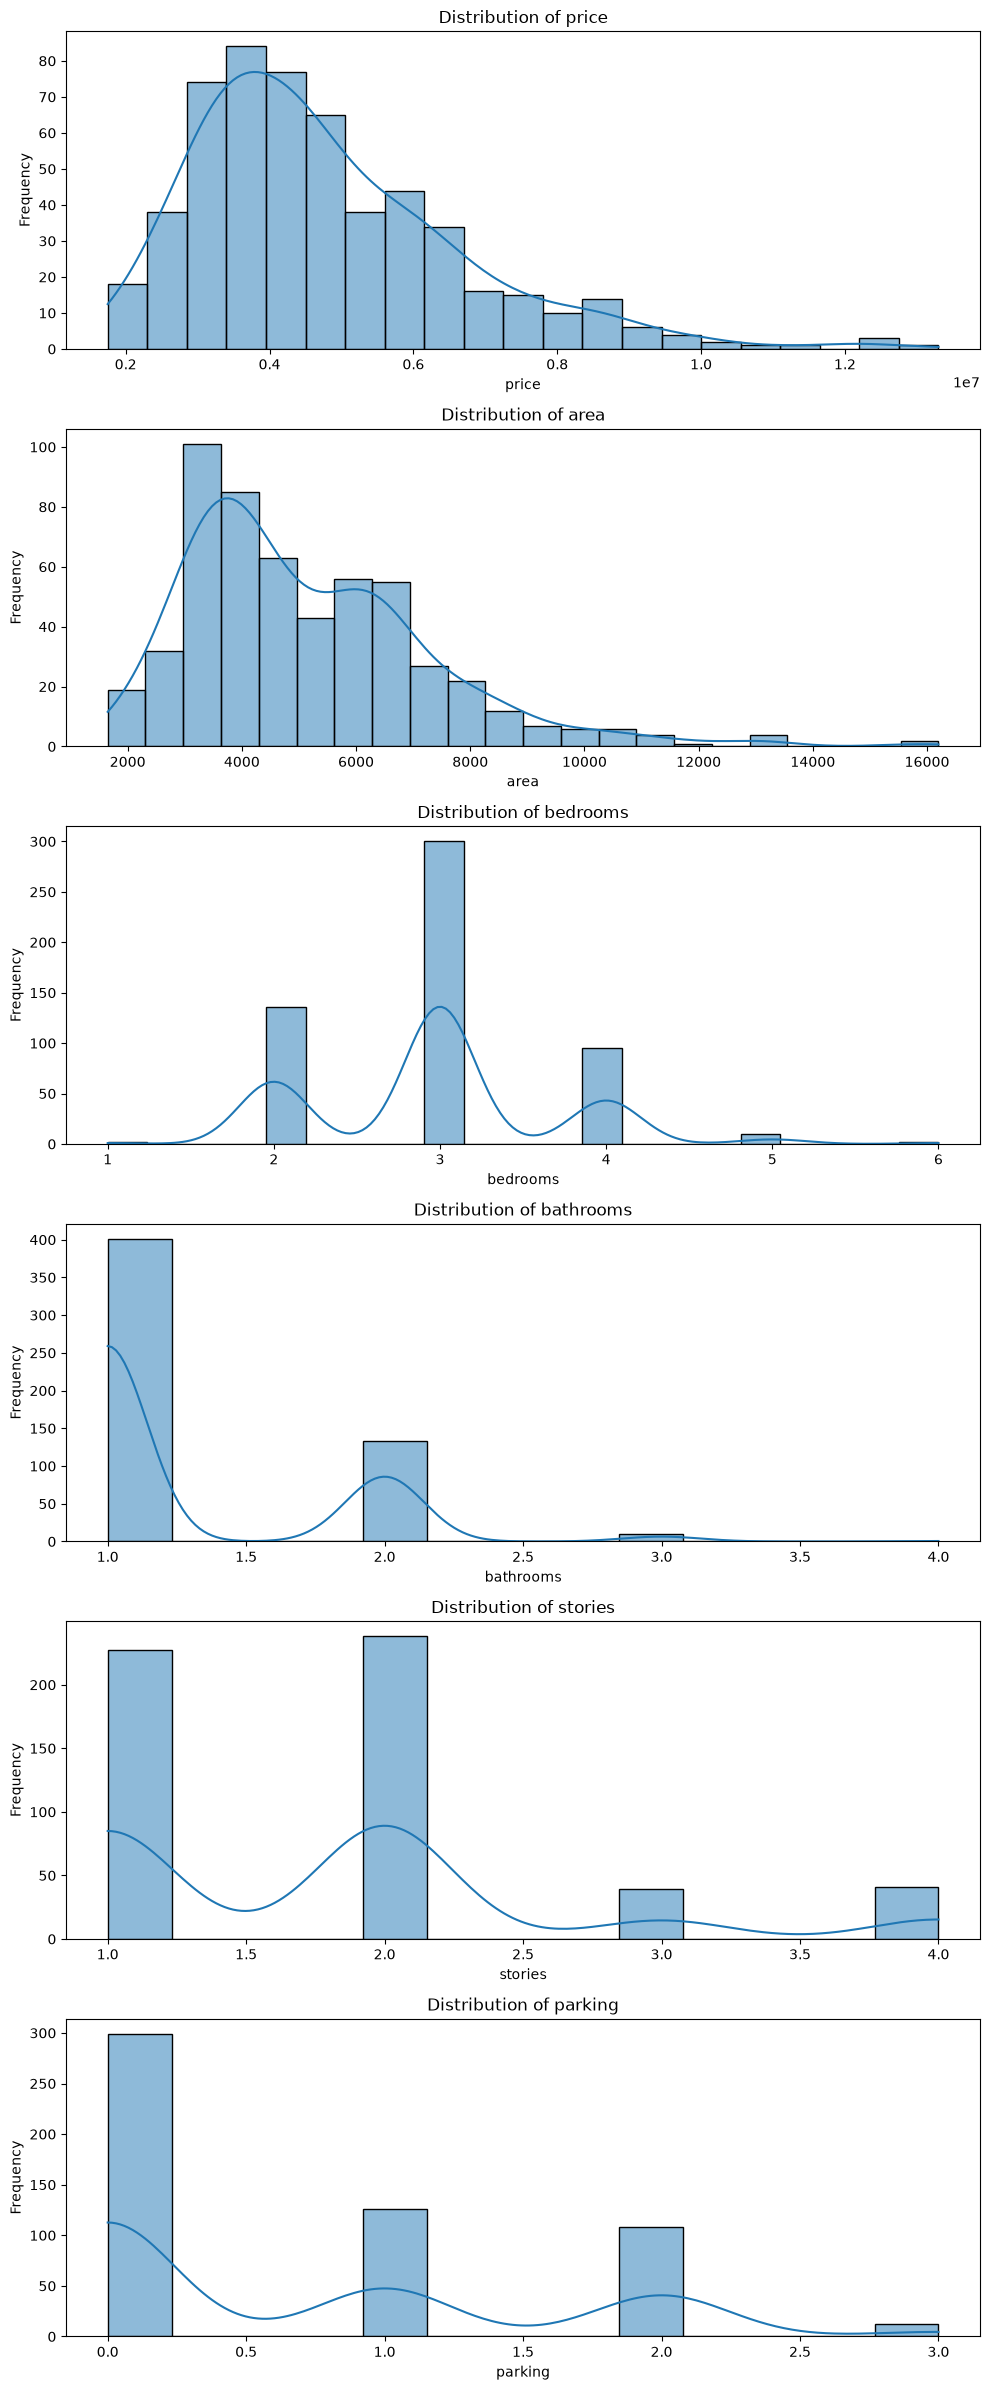

In [27]:
fig, axes = plt.subplots(
    nrows=len(numerical_features),
    ncols=1,
    figsize=(10, 4 * len(numerical_features))
)

for ax, column in zip(axes, numerical_features):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

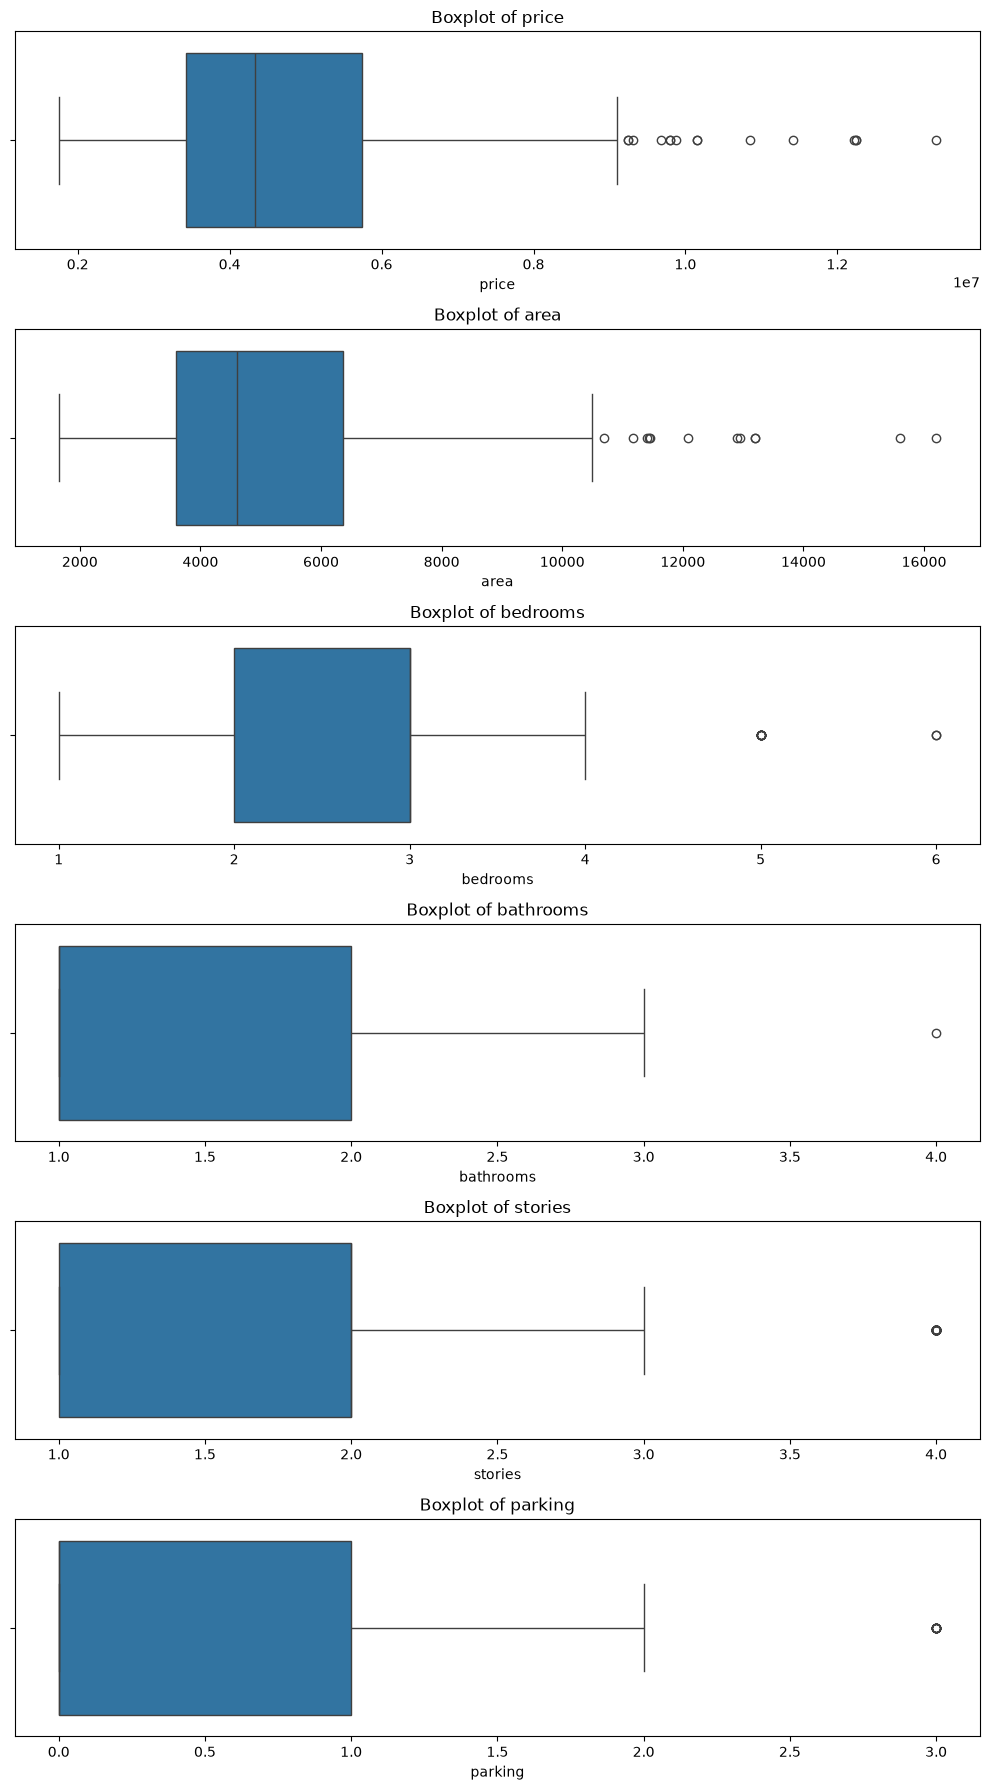

In [28]:
fig, axes = plt.subplots(
    nrows=len(numerical_features),
    ncols=1,
    figsize=(10, 3 * len(numerical_features))
)

for ax, column in zip(axes, numerical_features):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [29]:
skewness = df[numerical_features].skew().sort_values(ascending=False)

skewness

bathrooms    1.589264
area         1.321188
price        1.212239
stories      1.082088
parking      0.842062
bedrooms     0.495684
dtype: float64

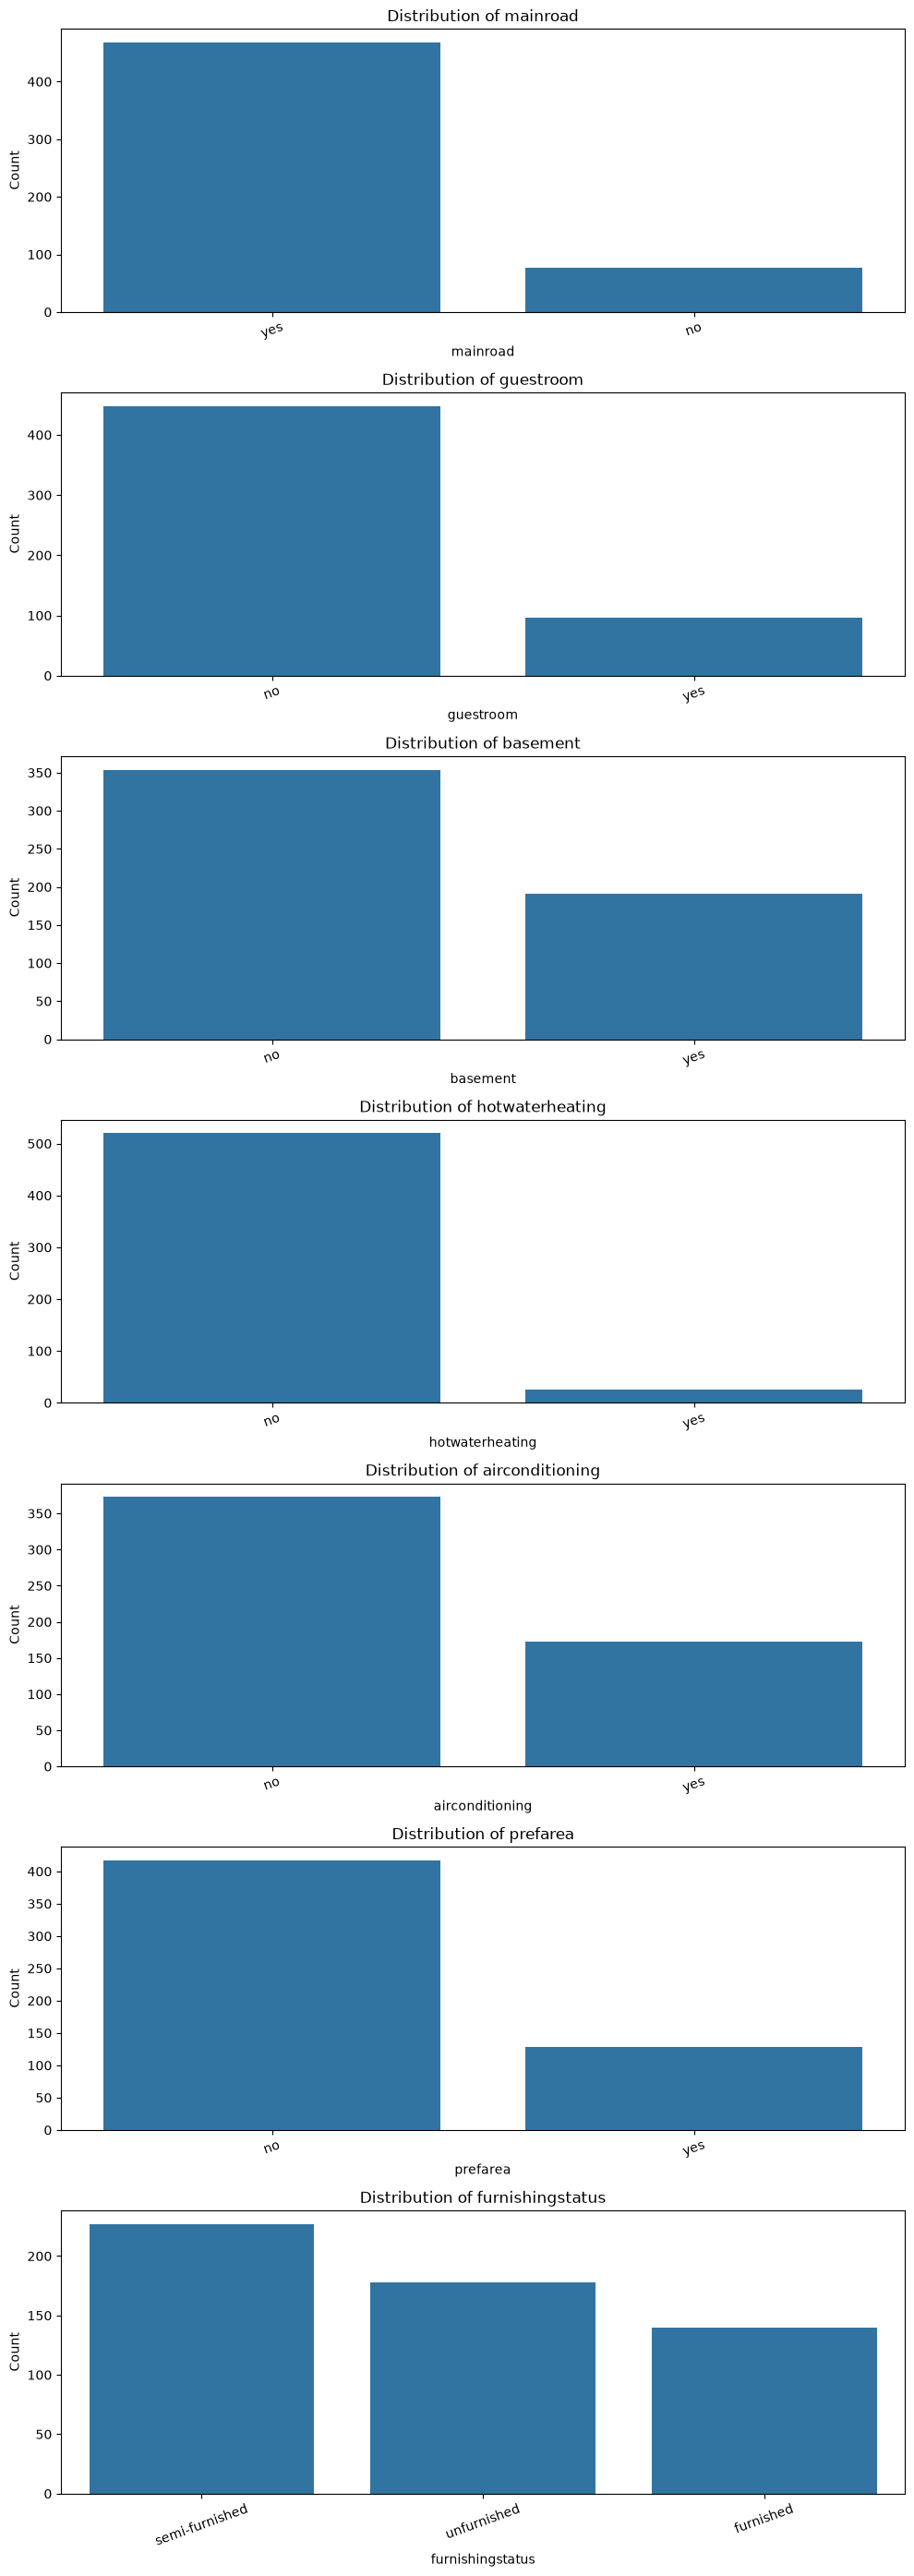

In [30]:
fig, axes = plt.subplots(
    nrows=len(categorical_features),
    ncols=1,
    figsize=(10, 4 * len(categorical_features))
)

for ax, column in zip(axes, categorical_features):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [31]:
#categorical frequency tables
for column in categorical_features:
    print(f"\n{column}")
    print(df[column].value_counts())


mainroad
mainroad
yes    468
no      77
Name: count, dtype: int64

guestroom
guestroom
no     448
yes     97
Name: count, dtype: int64

basement
basement
no     354
yes    191
Name: count, dtype: int64

hotwaterheating
hotwaterheating
no     520
yes     25
Name: count, dtype: int64

airconditioning
airconditioning
no     373
yes    172
Name: count, dtype: int64

prefarea
prefarea
no     417
yes    128
Name: count, dtype: int64

furnishingstatus
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64


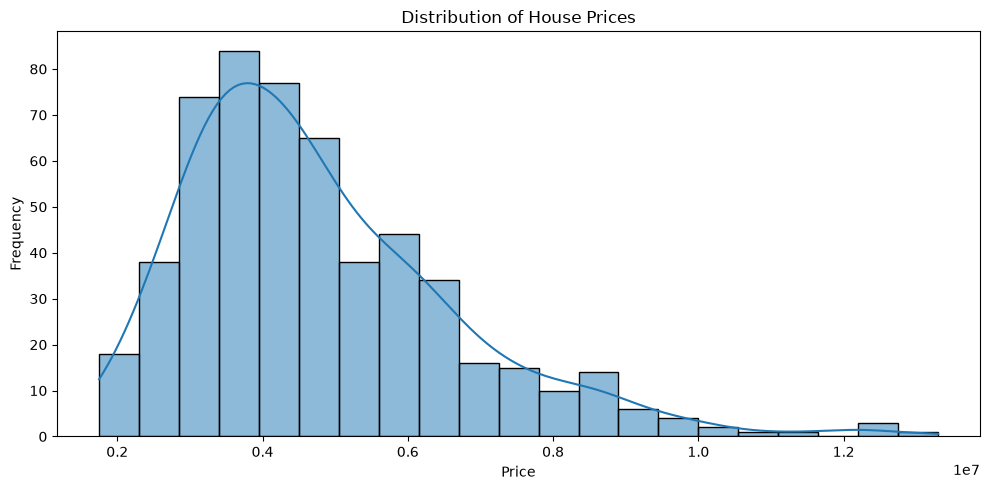

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", kde=True)
#target distribution
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

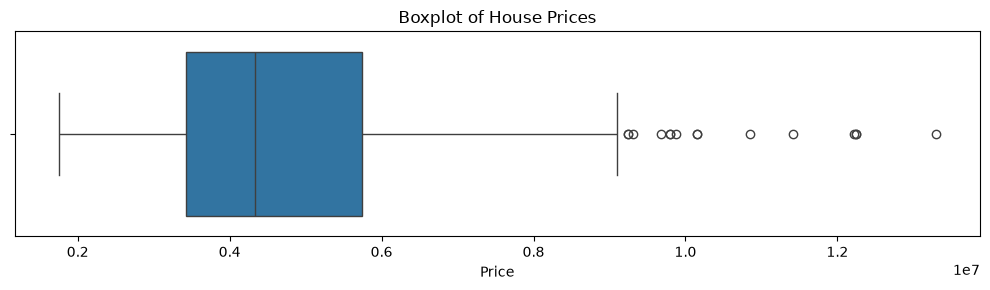

In [ ]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=df["price"])
#target boxplot
plt.title("Boxplot of House Prices")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

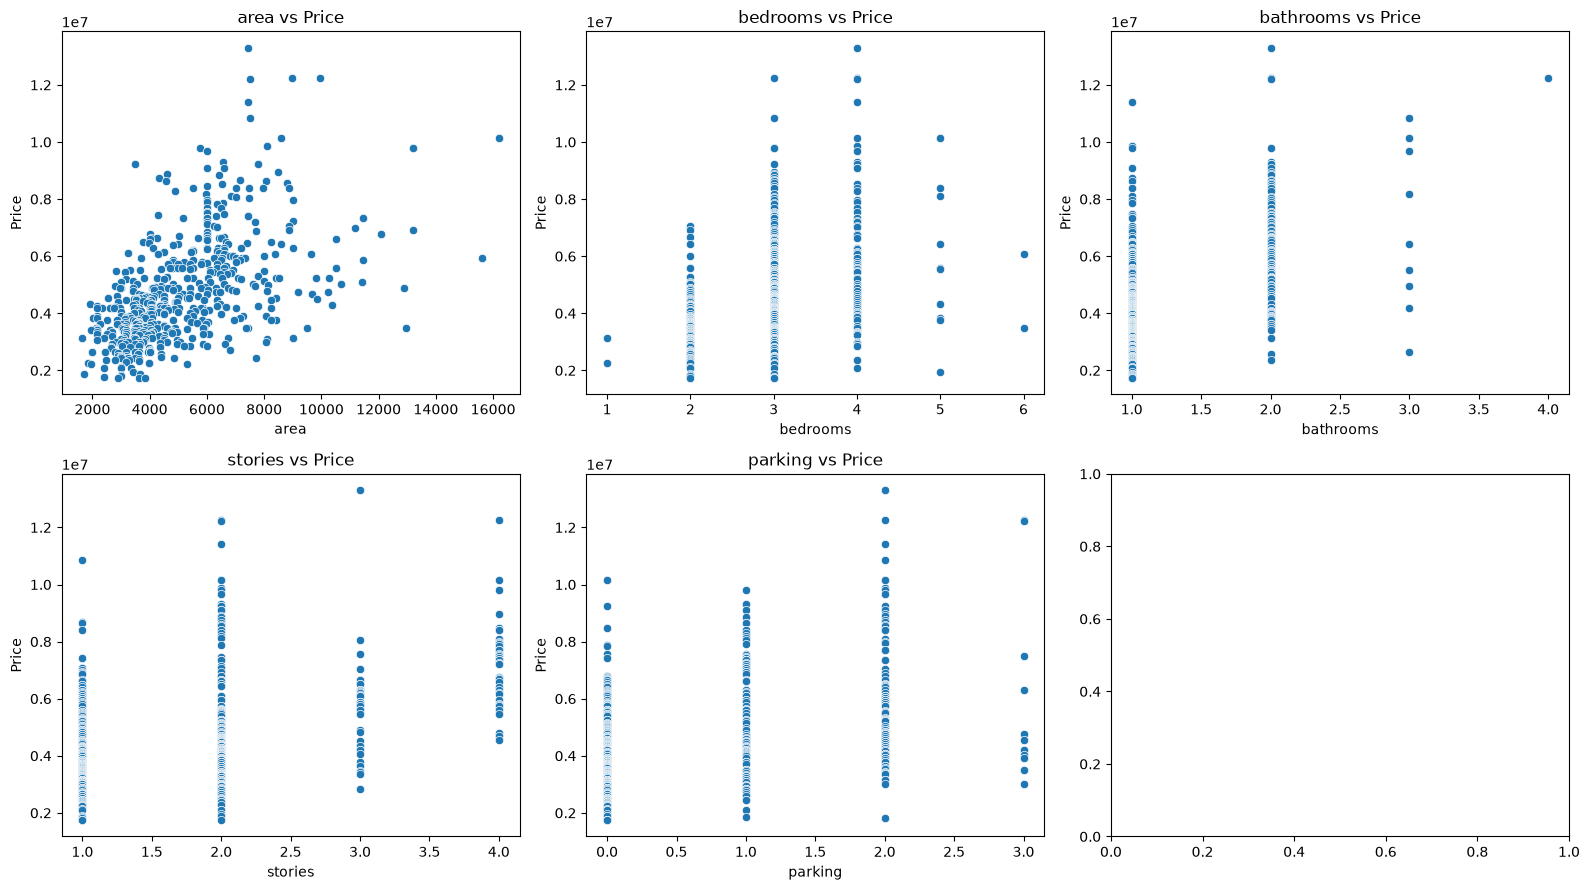

In [36]:
# Scatter plots help us visually examine the relationship between each
# numerical predictor and the target variable.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

for ax, column in zip(axes.flat, numerical_features.drop("price")):
    sns.scatterplot(data=df, x=column, y="price", ax=ax)
    ax.set_title(f"{column} vs Price")
    ax.set_xlabel(column)
    ax.set_ylabel("Price")

plt.tight_layout()
plt.show()

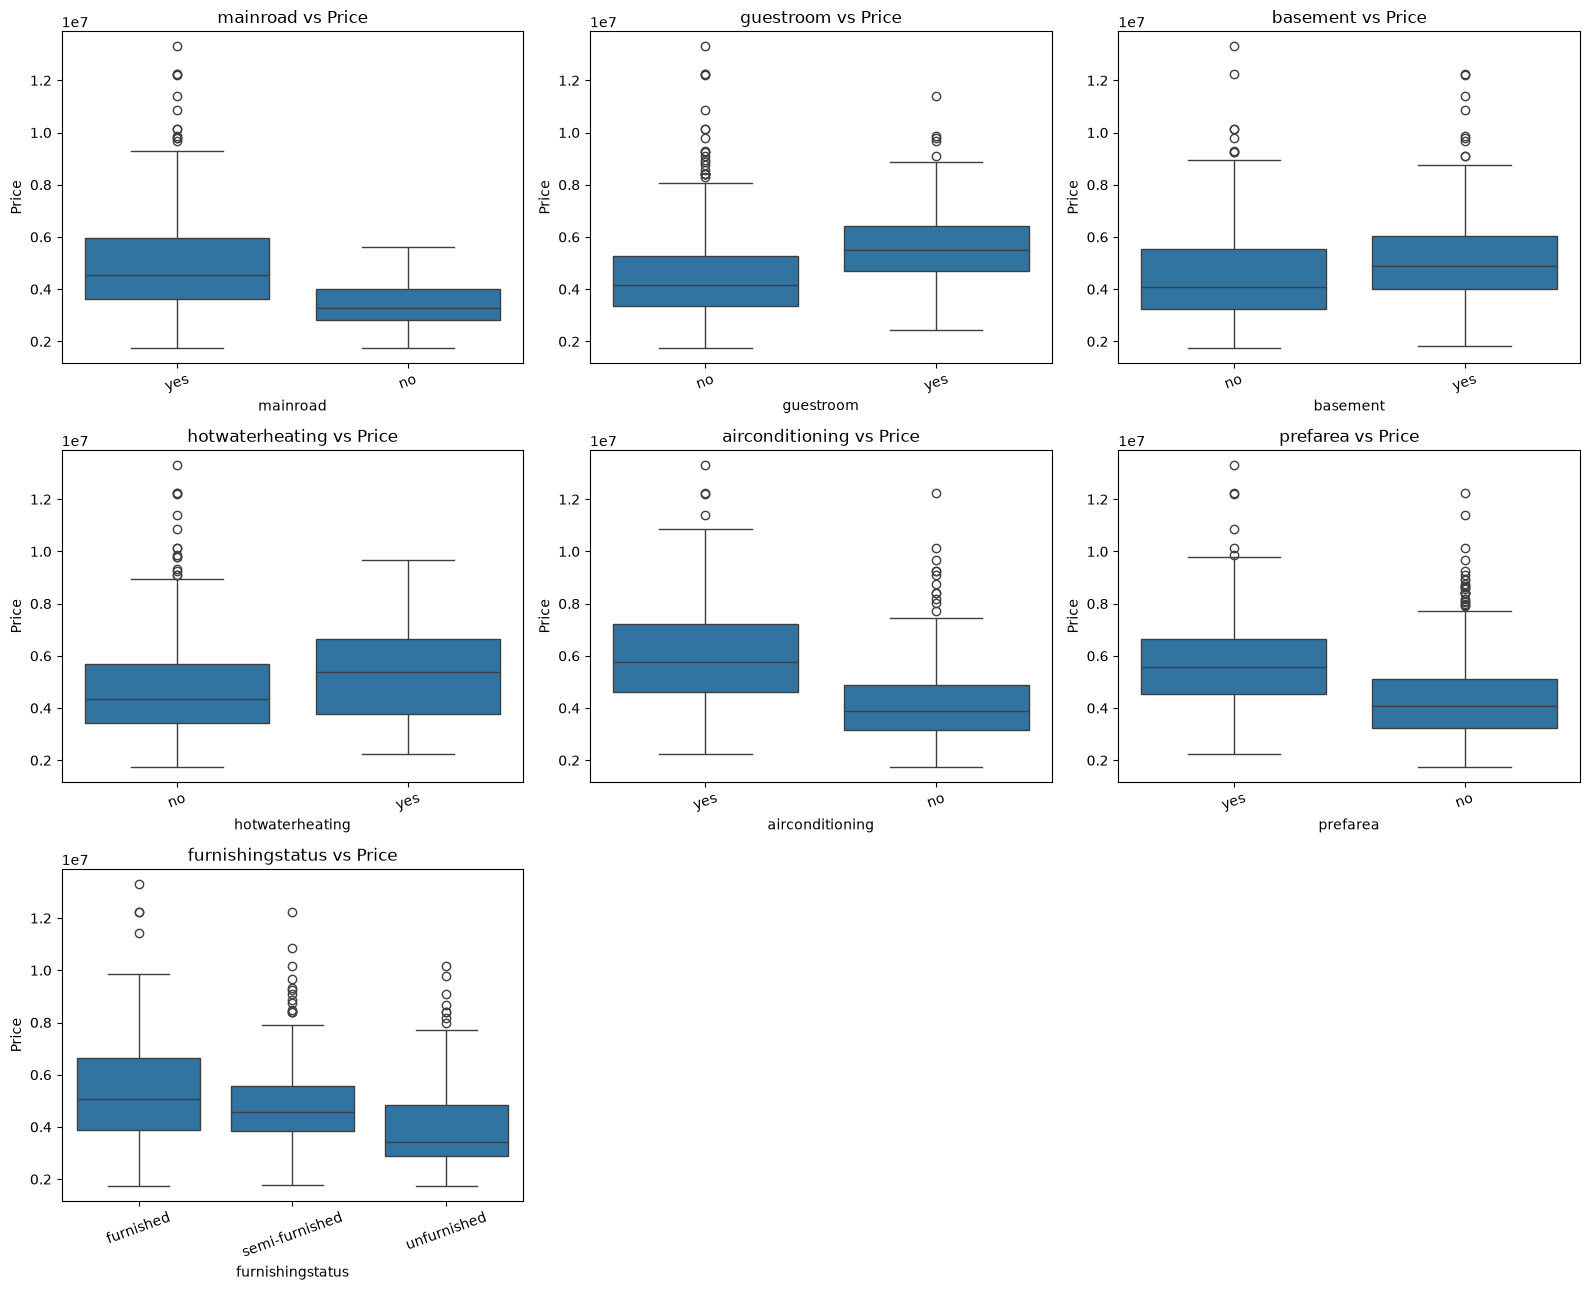

In [35]:
# Boxplots compare the distribution of house prices across categories.
fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(16, 13)
)

for ax, column in zip(axes.flat, categorical_features):
    sns.boxplot(data=df, x=column, y="price", ax=ax)
    ax.set_title(f"{column} vs Price")
    ax.set_xlabel(column)
    ax.set_ylabel("Price")
    ax.tick_params(axis="x", rotation=20)

# Hide unused subplot positions.
for ax in axes.flat[len(categorical_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [37]:
# Calculate correlations with price only; the complete correlation matrix
# will be handled separately in the correlation-analysis phase.
price_correlations = (
    df[numerical_features]
    .corr()["price"]
    .drop("price")
    .sort_values(ascending=False)
)

price_correlations

area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64

In [38]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix

,price,area,bedrooms,bathrooms,stories,parking
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547
parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000


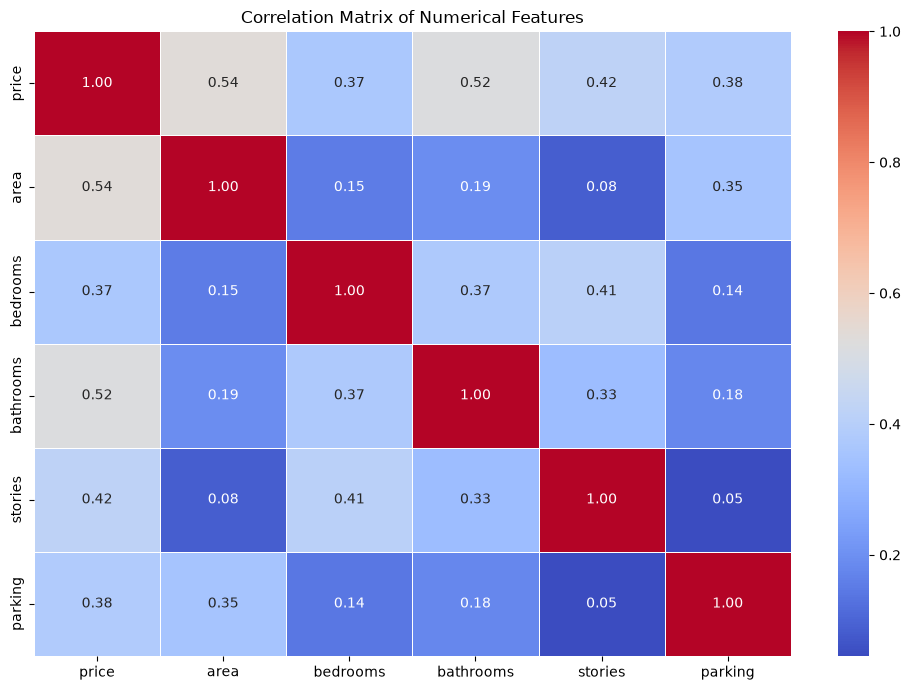

In [39]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [40]:
# Rank numerical predictors by their linear relationship with the target.
price_correlations = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(ascending=False)
)

price_correlations

area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64

In [41]:
# Identify strong relationships among independent numerical features.
feature_corr = correlation_matrix.drop(index="price", columns="price")

strong_correlations = (
    feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

strong_correlations

bedrooms   stories      0.408564
           bathrooms    0.373930
area       parking      0.352980
bathrooms  stories      0.326165
area       bathrooms    0.193820
bathrooms  parking      0.177496
area       bedrooms     0.151858
bedrooms   parking      0.139270
area       stories      0.083996
stories    parking      0.045547
area       area              NaN
bedrooms   area              NaN
           bedrooms          NaN
bathrooms  area              NaN
           bedrooms          NaN
           bathrooms         NaN
stories    area              NaN
           bedrooms          NaN
           bathrooms         NaN
           stories           NaN
parking    area              NaN
           bedrooms          NaN
           bathrooms         NaN
           stories           NaN
           parking           NaN
dtype: float64

 
The target variable `price` is separated from the predictor variables.
Categorical predictors are converted into numerical dummy variables so that
they can be used by the Linear Regression model.

The first category is dropped for each categorical feature to avoid redundant
dummy variables and unnecessary perfect multicollinearity.

In [47]:
from sklearn.preprocessing import OneHotEncoder

In [48]:
# handle_unknown='ignore' prevents errors if the test set contains a category
# that was not present in the training data.
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

In [46]:
print("Final number of features:", x.shape[1])
print("\nFeature data types:")
print(x.dtypes.value_counts())

Final number of features: 13

Feature data types:
int64    13
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import train_test_split

# Recreate x with all predictor columns before splitting.
x = df.drop(columns=target)
y = df[target]

# Split before fitting the encoder to prevent data leakage.
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)

Training data: (436, 12)
Testing data : (109, 12)


In [52]:
# Fit the encoder only on training categorical features.
x_train_cat = encoder.fit_transform(x_train[categorical_features])
x_test_cat = encoder.transform(x_test[categorical_features])

In [55]:
# Convert encoded features to DataFrames and combine with numerical features.
encoded_columns = encoder.get_feature_names_out(categorical_features)

x_train_cat = pd.DataFrame(
    x_train_cat,
    columns=encoded_columns,
    index=x_train.index
)

x_test_cat = pd.DataFrame(
    x_test_cat,
    columns=encoded_columns,
    index=x_test.index
)

# Remove the target from the numerical feature list before combining features.
numerical_predictors = [col for col in numerical_features if col != target]

x_train_processed = pd.concat(
    [x_train[numerical_predictors], x_train_cat],
    axis=1
)

x_test_processed = pd.concat(
    [x_test[numerical_predictors], x_test_cat],
    axis=1
)

print("Processed training data:", x_train_processed.shape)
print("Processed testing data :", x_test_processed.shape)

Processed training data: (436, 13)
Processed testing data : (109, 13)


Simple Linear Regression

Build a simple linear regression model using `area` as the single predictor
to predict house `price`.

In [56]:
from sklearn.linear_model import LinearRegression

# Use area as the single predictor for simple linear regression.
x_train_simple = x_train[["area"]]
x_test_simple = x_test[["area"]]

simple_model = LinearRegression()

# Train the model using only the training data.
simple_model.fit(x_train_simple, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[425.73]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.512e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [57]:
# Generate predictions for the test data.
y_pred_simple = simple_model.predict(x_test_simple)

print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

Intercept: 2512254.2639593435
Coefficient: 425.72984193878284


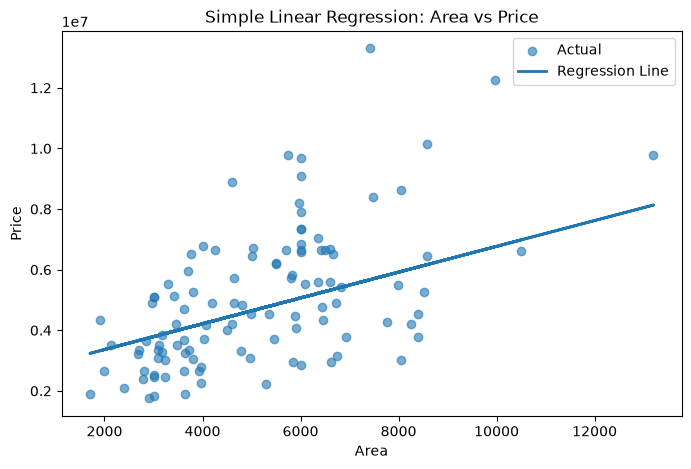

In [58]:
# Plot the actual data and fitted regression line.
plt.figure(figsize=(8, 5))

plt.scatter(x_test_simple["area"], y_test, alpha=0.6, label="Actual")
plt.plot(
    x_test_simple["area"],
    y_pred_simple,
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Simple Linear Regression: Area vs Price")
plt.legend()
plt.show()

In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate the required regression evaluation metrics.
mae_simple = mean_absolute_error(y_test, y_pred_simple)
mse_simple = mean_squared_error(y_test, y_pred_simple)
r2_simple = r2_score(y_test, y_pred_simple)

print("Simple Linear Regression Performance")
print("------------------------------------")
print(f"MAE : {mae_simple:.2f}")
print(f"MSE : {mse_simple:.2f}")
print(f"R²  : {r2_simple:.4f}")

Simple Linear Regression Performance
------------------------------------
MAE : 1474748.13
MSE : 3675286604768.19
R²  : 0.2729


In [60]:
# Compare actual and predicted prices for the test set.
simple_results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred_simple
})

simple_results.head(10)

,Actual Price,Predicted Price
316,4060000,5.024060e+06
77,6650000,5.279498e+06
360,3710000,4.232203e+06
90,6440000,4.640903e+06
493,2800000,4.198144e+06
209,4900000,5.373159e+06
176,5250000,6.139473e+06
249,4543000,4.636646e+06
516,2450000,3.891619e+06
426,3353000,3.661725e+06


### Conclusion

The simple linear regression model was trained using `area` to predict `price`.
The coefficient represents the expected change in house price for a one-unit
increase in area.

####  Multiple Linear Regression

Build a multiple linear regression model using all numerical and encoded
categorical features to predict house prices.

In [61]:
from sklearn.linear_model import LinearRegression

# Train the multiple linear regression model using all processed features.
multiple_model = LinearRegression()
multiple_model.fit(x_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 235.97, 76778.7 ,1094444.79,..., 629890.57,-126881.82,-413645.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea_yes', 'furnishingstatus_semi-furnished','furnishingstatus_unfurnished']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.6e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [62]:
# Generate predictions for the test data.
y_pred_multiple = multiple_model.predict(x_test_processed)

print("Intercept:", multiple_model.intercept_)
print("Number of coefficients:", len(multiple_model.coef_))

Intercept: 260032.35760741215
Number of coefficients: 13


In [63]:
# Store coefficients with their corresponding feature names.
coefficients = pd.DataFrame({
    "Feature": x_train_processed.columns,
    "Coefficient": multiple_model.coef_
})

coefficients

,Feature,Coefficient
0,area,2.359688e+02
1,bedrooms,7.677870e+04
2,bathrooms,1.094445e+06
3,stories,4.074766e+05
4,parking,2.248419e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
7,basement_yes,3.902512e+05
8,hotwaterheating_yes,6.846499e+05
9,airconditioning_yes,7.914267e+05


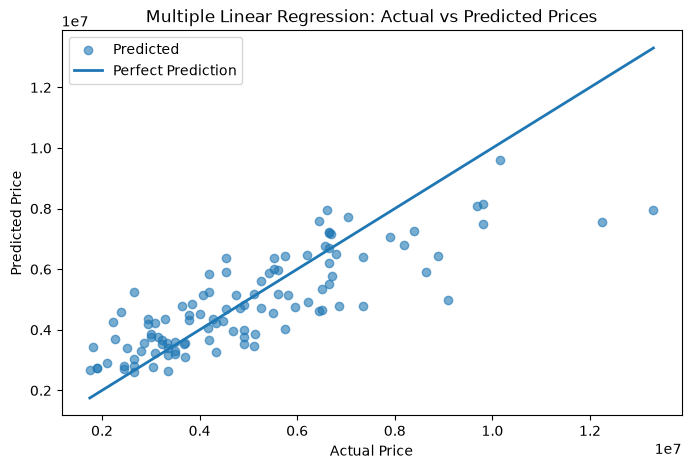

In [66]:
# Plot actual vs predicted prices.
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_multiple, alpha=0.6, label="Predicted")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression: Actual vs Predicted Prices")
plt.legend()
plt.show()

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics for the multiple regression model.
mae_multiple = mean_absolute_error(y_test, y_pred_multiple)
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
r2_multiple = r2_score(y_test, y_pred_multiple)

print("Multiple Linear Regression Performance")
print("--------------------------------------")
print(f"MAE : {mae_multiple:.2f}")
print(f"MSE : {mse_multiple:.2f}")
print(f"R²  : {r2_multiple:.4f}")

Multiple Linear Regression Performance
--------------------------------------
MAE : 970043.40
MSE : 1754318687330.66
R²  : 0.6529


Simple vs Multiple Regression

In [68]:
# Compare both regression models using the required metrics.
model_comparison = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "MAE": [mae_simple, mae_multiple],
    "MSE": [mse_simple, mse_multiple],
    "R²": [r2_simple, r2_multiple]
})

model_comparison

,Model,MAE,MSE,R²
0,Simple Linear Regression,1.474748e+06,3.675287e+12,0.272879
1,Multiple Linear Regression,9.700434e+05,1.754319e+12,0.652924
